Code to calculate the ratio-fluences between the 3 methods of measurments

input: burst_stats_r117.csv

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.gridspec as gridspec
import pandas as pd
import os
from matplotlib import rcParams

In [2]:
def load_df(file, pband=False, lband=False):
    "Load in the dataframe"
    
    fluence_df = pd.read_csv(file, sep=",", header=0, index_col=0, na_values='NA', engine='python')
    print(fluence_df['src'].unique())
    
    ##Remove Stockert from the dataframe
    fluence_df_diff = fluence_df[fluence_df['experiment'] != 'stocke']
    
    #Filter on L-band (EU) or P-band (328 MHz)
    if pband == True:
        fluence_df_diff = fluence_df_diff[fluence_df_diff['f0_MHz'] == 328]
        
    elif lband == True:
        fluence_df_diff = fluence_df_diff[fluence_df_diff['f0_MHz'] != 328]
        
    return fluence_df_diff

In [3]:
def fluence(fluence_df, src):
    
    "return the array with fluence values"
    fluence_list = []
    exps = fluence_df['id'].unique()
    fluence_df_config_temp = fluence_df[(fluence_df['src'] == src)]

    for exp in exps:
        fluence_df_exp_temp = fluence_df_config_temp[fluence_df_config_temp['id'] == exp]
        fluence = sum(fluence_df_exp_temp['fluence_jyms'].values)
        fluence_list.append(fluence)

    fluence_array = np.asarray(fluence_list)
    return fluence_array

In [4]:
def sort_fluence(fluence_df_diff):
    #list of all experiments over which we can loop
    ids = fluence_df_diff['id'].unique()
    configs = fluence_df_diff['src'].unique()

    fluence_scale = fluence(fluence_df_diff, src='scale')
    fluence_spc = fluence(fluence_df_diff, src='spc')
    fluence_sfxc = fluence(fluence_df_diff, src='sfxc')

    #Order burst from large to small Fluence
    zip_ordered = sorted(zip(fluence_scale, fluence_spc, fluence_sfxc, ids), reverse=True)
    fluences_sorted = list(zip(*zip_ordered))

    data_fl = {'scale': fluences_sorted[0], 'spc': fluences_sorted[1], 'sfxc':fluences_sorted[2], 'id':fluences_sorted[3]}
    df = pd.DataFrame(data=data_fl)
    display(df)

    return df

In [5]:
def burst_info(file, pband=False, lband=False):

    print(pband)
    fluence_df_diff_p = load_df(file, pband, lband)
    df_fluences_sorted = sort_fluence(fluence_df_diff_p)
    
    return df_fluences_sorted

In [6]:
df_fluences_sorted_p = burst_info(file="../dbs/burst_stats_r117.csv", pband=True)

True
['sfxc' 'scale' 'spc']


,scale,spc,sfxc,id
0,2657.327776,2629.400017,2558.058318,B128-wb
1,1387.827942,1370.936285,1368.726741,B121-wb
2,1076.421475,1049.004883,925.523967,B125-wb
3,838.927663,826.577109,774.016683,B117-wb
4,789.586996,782.968200,729.911837,B120-wb
5,727.196869,720.248429,722.055931,B115-wb
6,567.378472,558.939056,543.847320,B119-wb
7,460.166835,453.575662,479.373754,B100-wb
8,381.771393,372.148526,368.142287,B110-wb
9,326.392748,320.784860,292.071009,B126-wb


In [7]:
df_fluences_sorted_l = burst_info(file="../dbs/burst_stats_r117.csv", lband=True)

False
['sfxc' 'scale' 'spc']


,scale,spc,sfxc,id
0,1761.206894,1587.281577,1001.702708,B68-wb
1,747.540498,684.009354,490.058840,B46-wb
2,741.313355,662.115202,473.353994,B52-wb
3,480.837275,447.277097,353.841017,B107-wb
4,442.824263,408.441795,309.216543,B85-wb
5,336.062676,321.621571,270.805656,B15-wb
6,330.506690,314.501665,259.449385,B37-wb
7,279.805276,251.053373,182.949011,B101-wb
8,249.734218,228.710311,160.356382,B15-tr
9,148.394267,132.160094,104.926107,B07-tr


In [8]:
def fluence_plot(fluence_df, band):
    
    if band == 'L':
        print("I dropped the following row:")
        fluence_df_tst = fluence_df[(fluence_df == 0).any(axis=1)]
        display(fluence_df_tst)
        
        fluence_df = fluence_df[~(fluence_df == 0).any(axis=1)]
        
    fluences_scale = fluence_df['scale'].values
    fluences_spc = fluence_df['spc'].values
    fluences_sfxc = fluence_df['sfxc'].values
    burst_id = fluence_df['id'].values
    
    x_grid = np.arange(1, len(fluences_scale)+1)
    
    fig, ax = plt.subplots(figsize=(10, 10))

    ax.scatter(fluences_spc, fluences_scale/fluences_spc, label="digifil/SPC", marker="^", s=80)
    ax.scatter(fluences_spc, fluences_sfxc/fluences_spc, label="SFXC/SPC", marker="o", s=80)
    ax.axhline(1, color='red', linestyle='-.')

    ax.set_ylabel("Fluence ratio", fontsize=24)
    ax.set_xlabel(r"SPC-corrected Fluence [Jy$\,$ms]", fontsize=24)

    ax.legend(fontsize=16)
    
    if band == 'P':
        save_fig = 'pband'
        ax.set_ylim(0.42,1.58)
        ax.set_xlim(100,3800)
        
    elif band == 'L':
        save_fig = 'lband'       
        ax.set_ylim(0.5,1.5)
        ax.set_xlim(5,2000)
        
    ax.set_xscale('log')
    ax.tick_params(axis='both', which='major', labelsize=20)   

    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
    
    ax.tick_params(axis='y', which='major', direction='in', length=10, width=2)
    ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
    ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)
    
    ax.tick_params(axis='x', which='both', top=True)
            
    plt.savefig(f"../plots/fluence_ratio_{save_fig}.pdf", bbox_inches='tight',
               facecolor='white', transparent=False, dpi=600)
    plt.show()

In [9]:
#fluence_plot(df_fluences_sorted_p, 'P')

In [10]:
##Note there is an entry with 0-0-0, hence we skip the first one
#fluence_plot(df_fluences_sorted_l, 'L')

I dropped the following row:


,scale,spc,sfxc,id
45,0.0,0.0,0.0,B130-tr


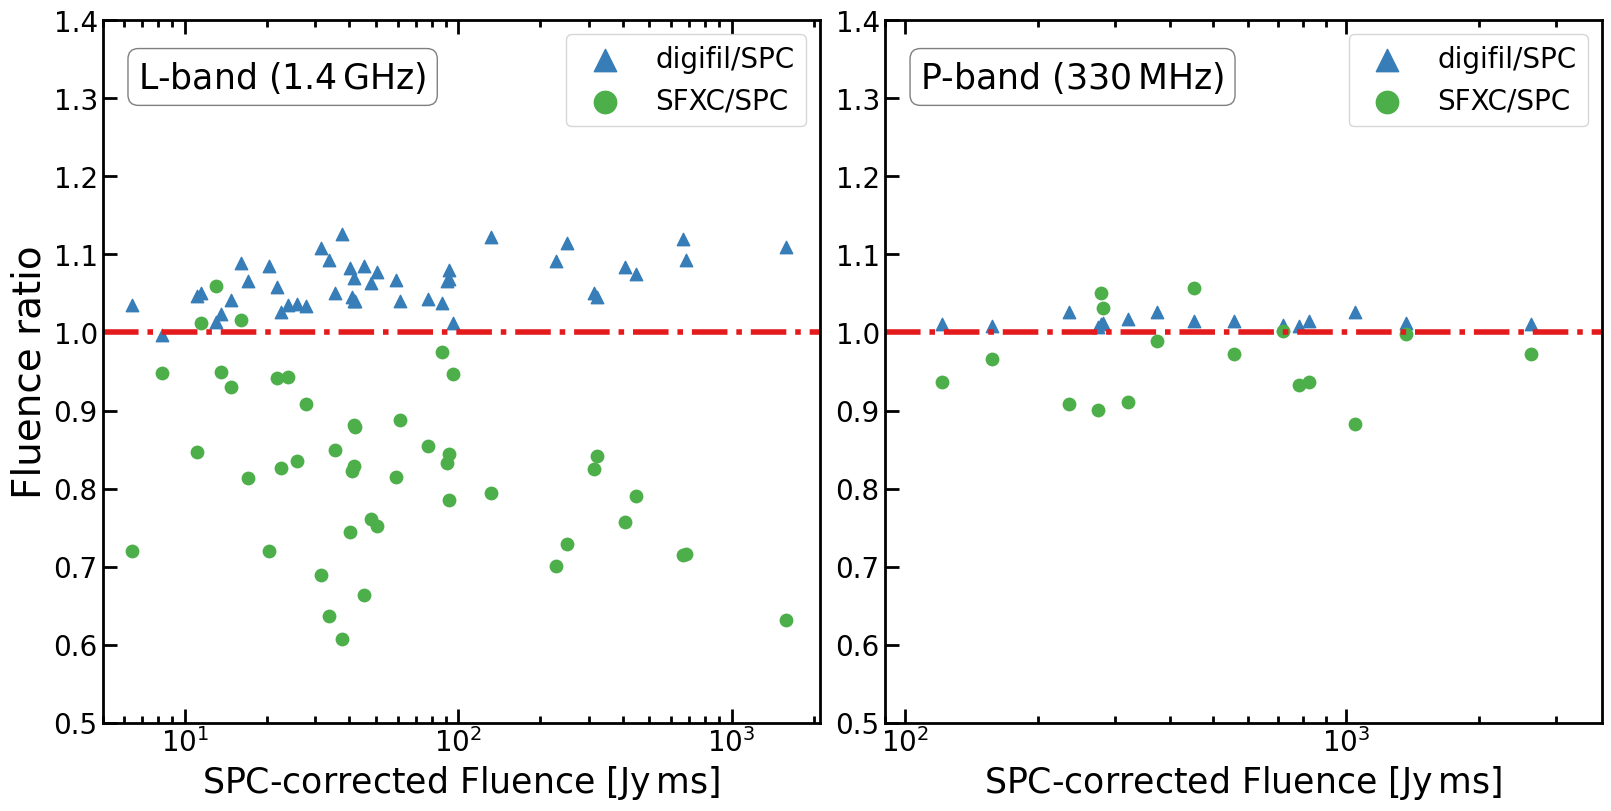

In [58]:
def fluence_plot_panels(fluence_df_l, fluence_df_p):
    
    print("I dropped the following row:")
    fluence_df_l_tst = fluence_df_l[(fluence_df_l == 0).any(axis=1)]
    display(fluence_df_l_tst)        
    fluence_df_l = fluence_df_l[~(fluence_df_l == 0).any(axis=1)]
                  
    fig5 = plt.figure(constrained_layout=True, figsize=(16, 8))
    widths = [2, 2]
    heights = [1]
    spec5 = fig5.add_gridspec(ncols=2, nrows=1, width_ratios=widths,
                              height_ratios=heights)
    
    ax1 = fig5.add_subplot(spec5[0, 0])
    ax2 = fig5.add_subplot(spec5[0, 1], sharey=ax1)

    for ax, fluence_df in zip([ax1,ax2], [fluence_df_l,fluence_df_p]):

        fluences_scale = fluence_df['scale'].values
        fluences_spc = fluence_df['spc'].values
        fluences_sfxc = fluence_df['sfxc'].values
        burst_id = fluence_df['id'].values

        x_grid = np.arange(1, len(fluences_scale)+1)

        ax.scatter(fluences_spc, fluences_scale/fluences_spc, label="digifil/SPC", marker="^", s=80, color="#377eb8")
        ax.scatter(fluences_spc, fluences_sfxc/fluences_spc, label="SFXC/SPC", marker="o", s=80, color="#4daf4a")
        ax.axhline(1, color='#e41a1c', linestyle='-.', lw=4)
    
        ax.set_xlabel(r"SPC-corrected Fluence [Jy$\,$ms]", fontsize=25)

        ax.legend(fontsize=20, loc='upper right',markerscale=1.8, fancybox=True)
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)   
    
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
        
        ax.tick_params(axis='y', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)
        ax.tick_params(axis='x', which='both', top=True)
        
    #Lband
    ax1.set_ylabel("Fluence ratio", fontsize=28)
    ax1.set_ylim(0.5,1.4)
    ax1.set_xlim(5,2100)
    
    props = dict(boxstyle='round', facecolor='white', alpha=0.5)
    
    ax1.text(0.05, 0.945, r'L-band ($1.4\,\mathrm{GHz}$)', transform=ax1.transAxes, fontsize=25,
        verticalalignment='top', bbox=props)
    ax2.text(0.05, 0.945, r'P-band ($330\,\mathrm{MHz}$)', transform=ax2.transAxes, fontsize=25,
        verticalalignment='top', bbox=props)
    #Pband
    ax2.set_xlim(90,3800)
    
    plt.savefig(f"../plots/fluence_ratio_PL.pdf", bbox_inches='tight',\
               facecolor='white', transparent=False, dpi=600)
        
    plt.savefig(f"../plots/fluence_ratio_PL.png", facecolor='white', \
                        transparent=False, format = 'png',bbox_inches='tight', dpi=600)
    plt.show()
    
fluence_plot_panels(df_fluences_sorted_l,df_fluences_sorted_p)